# Ames Housing — Regression: Predicting `Year Built`

**Research Question:** Given a house's physical characteristics and quality
attributes, can we predict its **construction year**?

> **Prerequisite:** run `preprocessing.ipynb` first to generate `preprocessed_data.pkl`.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from scipy.stats import uniform

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV

In [16]:
with open('../data/processed/preprocessed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X            = data['X']
y            = data['y']
X_train      = data['X_train']
X_test       = data['X_test']
y_train      = data['y_train']
y_test       = data['y_test']
preprocessor = data['preprocessor']

print(f'X_train : {X_train.shape}  |  X_test : {X_test.shape}')
print(f'y range : {int(y.min())} to {int(y.max())}')

X_train : (2344, 71)  |  X_test : (586, 71)
y range : 1872 to 2010


## Model Selection

Nine regressors are included to cover a broad range of learning strategies: a linear baseline (Linear Regression), a regularised linear model (Ridge), a decision tree, random forest, gradient boosting, XGBoost, support vector regression, k-nearest neighbours, and a multi-layer perceptron. Note: Polynomial Regression was replaced with Ridge because applying degree-2 expansion to the 150+ preprocessed features produces an ill-conditioned ~11,000-feature matrix that makes ordinary least squares numerically unstable.

In [17]:
models = {
    'Linear Regression':      LinearRegression(),
    'Ridge Regression':       Ridge(alpha=1.0),
    'Decision Tree':          DecisionTreeRegressor(random_state=42),
    'Random Forest':          RandomForestRegressor(random_state=42),
    'Gradient Boosting':      GradientBoostingRegressor(random_state=42),
    'XGBoost':                XGBRegressor(random_state=42),
    'Support Vector Regressor': SVR(),
    'K-Nearest Neighbors':    KNeighborsRegressor(n_neighbors=5),
    'Neural Network':         MLPRegressor(random_state=42, max_iter=2000),
}

In [18]:
def evaluation_matrix(model_name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)
    return {
        'Model': model_name,
        'MAE':   round(mae,  4),
        'MSE':   round(mse,  4),
        'RMSE':  round(rmse, 4),
        'R2':    round(r2,   4),
    }

## Training & Evaluation

In [19]:
trained_models = {}
eval_matrix    = []

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        # clone() gives each model a fresh, unfitted copy so that fitting one
        # model in this loop cannot affect the parameters used by another.
        ('model', clone(model)),
    ])
    pipeline.fit(X_train, y_train)
    # Split transform and predict so the same transformed test matrix can be
    # reused below (Actual vs Predicted plot) without repeating the ColumnTransformer step.
    X_test_t = pipeline[:-1].transform(X_test)
    y_pred   = pipeline[-1].predict(X_test_t)
    trained_models[model_name] = y_pred
    eval_matrix.append(evaluation_matrix(model_name, y_test, y_pred))

print('Training complete.')

Training complete.


In [20]:
eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,7.1369,95.4389,9.7693,0.8912
1,Ridge Regression,7.0690,93.7869,9.6844,0.8931
2,Decision Tree,3.0358,64.9983,8.0622,0.9259
3,Random Forest,2.2347,26.8619,5.1828,0.9694
4,Gradient Boosting,3.5746,39.1551,6.2574,0.9554
5,XGBoost,2.6954,28.7420,5.3612,0.9672
6,Support Vector Regressor,6.8144,122.8019,11.0816,0.8600
7,K-Nearest Neighbors,4.8884,71.1572,8.4355,0.9189
8,Neural Network,4.7422,70.9132,8.4210,0.9191


In [21]:
best_mae_idx  = eval_matrix_df['MAE'].idxmin()
best_mse_idx  = eval_matrix_df['MSE'].idxmin()
best_rmse_idx = eval_matrix_df['RMSE'].idxmin()
best_r2_idx   = eval_matrix_df['R2'].idxmax()

best_row = {
    'Model': 'Best Model',
    'MAE':   eval_matrix_df.loc[best_mae_idx,  'Model'],
    'MSE':   eval_matrix_df.loc[best_mse_idx,  'Model'],
    'RMSE':  eval_matrix_df.loc[best_rmse_idx, 'Model'],
    'R2':    eval_matrix_df.loc[best_r2_idx,   'Model'],
}
pd.concat([eval_matrix_df, pd.DataFrame([best_row])], ignore_index=True)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,7.1369,95.4389,9.7693,0.8912
1,Ridge Regression,7.069,93.7869,9.6844,0.8931
2,Decision Tree,3.0358,64.9983,8.0622,0.9259
3,Random Forest,2.2347,26.8619,5.1828,0.9694
4,Gradient Boosting,3.5746,39.1551,6.2574,0.9554
5,XGBoost,2.6954,28.742,5.3612,0.9672
6,Support Vector Regressor,6.8144,122.8019,11.0816,0.86
7,K-Nearest Neighbors,4.8884,71.1572,8.4355,0.9189
8,Neural Network,4.7422,70.9132,8.421,0.9191
9,Best Model,Random Forest,Random Forest,Random Forest,Random Forest


## Cross-Validation (5-Fold)

In [22]:
cv_results = []
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    # neg_mean_squared_error is used because scikit-learn's scoring convention
    # requires higher values to indicate better performance; negating MSE
    # before the square root recovers RMSE in its usual (positive) units.
    # Restricted to the training fold only, so the held-out test set used for
    # the final evaluation above is never seen during this stability check.
    scores      = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    rmse_scores = np.sqrt(-scores)
    cv_results.append({
        'Model':         name,
        'CV RMSE mean':  f'{rmse_scores.mean():.4f}',
        'CV RMSE std':   f'+/- {rmse_scores.std():.4f}',
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df


,Model,CV RMSE mean,CV RMSE std
0,Linear Regression,10.2453,+/- 0.5779
1,Ridge Regression,10.1412,+/- 0.5945
2,Decision Tree,8.7269,+/- 0.9697
3,Random Forest,5.6383,+/- 0.3641
4,Gradient Boosting,6.2085,+/- 0.1697
5,XGBoost,5.9506,+/- 0.2624
6,Support Vector Regressor,12.9372,+/- 1.0125
7,K-Nearest Neighbors,9.0324,+/- 0.8398
8,Neural Network,14.1477,+/- 2.2764


## Actual vs Predicted Construction Year

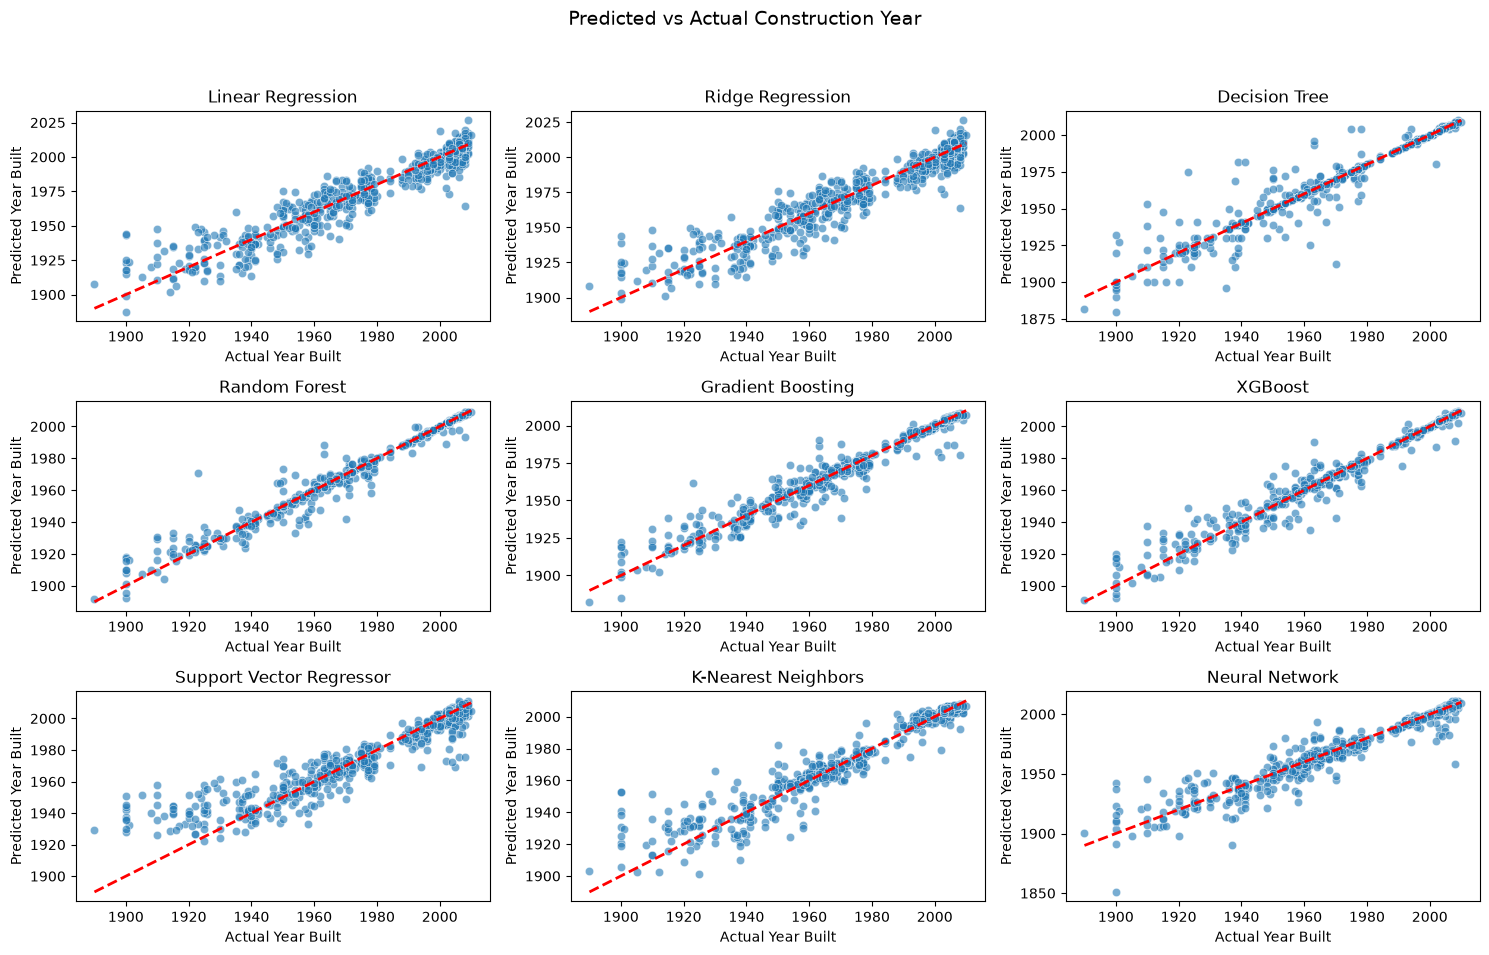

In [23]:
plt.figure(figsize=(15, 10))
plt.suptitle('Predicted vs Actual Construction Year', fontsize=14)

for i, (name, y_pred) in enumerate(trained_models.items(), 1):
    plt.subplot(3, 3, i)
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.xlabel('Actual Year Built')
    plt.ylabel('Predicted Year Built')
    plt.title(name)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## Feature Importance (Default Random Forest and XGBoost)

Mean-decrease-in-impurity feature importance is extracted from the two best-performing default models to check which predictors they actually rely on. This is a measure of predictive contribution within these specific models, not a causal effect, and it is reported only for the two models for which it is cheap and standard to compute (`feature_importances_`).


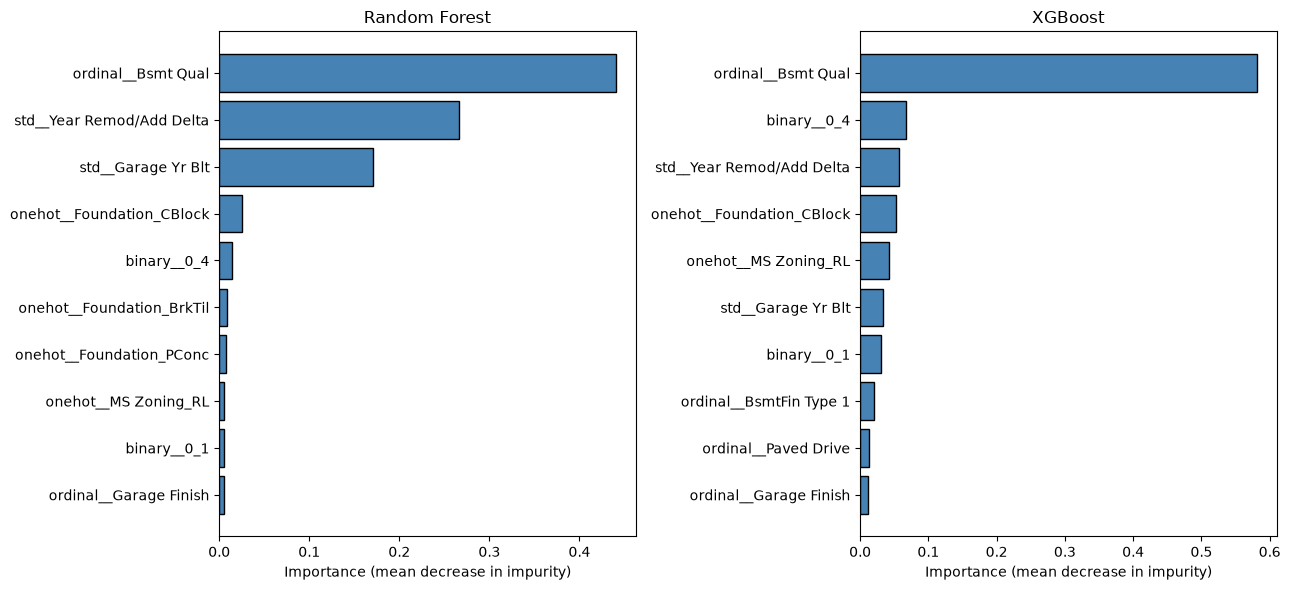

Random Forest -- top 3 features:
  ordinal__Bsmt Qual             0.4406
  std__Year Remod/Add Delta      0.2667
  std__Garage Yr Blt             0.1706

XGBoost -- top 3 features:
  ordinal__Bsmt Qual             0.5813
  binary__0_4                    0.0665
  std__Year Remod/Add Delta      0.0573



In [24]:
top_models_fi = {
    'Random Forest': RandomForestRegressor(random_state=42),
    'XGBoost':       XGBRegressor(random_state=42),
}
fitted_fi = {}
for name, model in top_models_fi.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', clone(model))])
    pipe.fit(X_train, y_train)
    fitted_fi[name] = pipe

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (name, pipe) in zip(axes, fitted_fi.items()):
    feat_names  = pipe.named_steps['preprocessor'].get_feature_names_out()
    importances = pipe.named_steps['model'].feature_importances_
    top_idx     = np.argsort(importances)[-10:]
    ax.barh(range(len(top_idx)), importances[top_idx], color='steelblue', edgecolor='black')
    ax.set_yticks(range(len(top_idx)))
    ax.set_yticklabels([feat_names[i] for i in top_idx])
    ax.set_xlabel('Importance (mean decrease in impurity)')
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name, pipe in fitted_fi.items():
    feat_names  = pipe.named_steps['preprocessor'].get_feature_names_out()
    importances = pipe.named_steps['model'].feature_importances_
    top3 = np.argsort(importances)[::-1][:3]
    print(f'{name} -- top 3 features:')
    for i in top3:
        print(f'  {feat_names[i]:30s} {importances[i]:.4f}')
    print()


## Hyperparameter Tuning

Top 4 performers tuned with cross-validated search:
- **Random Forest** & **XGBoost** → `RandomizedSearchCV` (large grid)
- **Gradient Boosting** & **SVR** → `GridSearchCV`

In [25]:
param_grids = {
    'Random Forest': {
        'model__n_estimators':      [50, 100, 200],
        'model__max_depth':         [None, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf':  [1, 2, 4],
    },
    'Gradient Boosting': {
        'model__n_estimators':  [50, 100, 200],
        'model__learning_rate': [0.01, 0.1, 0.2],
        'model__max_depth':     [3, 5, 7],
    },
    'XGBoost': {
        'model__n_estimators':  [50, 100, 200],
        'model__learning_rate': uniform(0.01, 0.3),
        'model__max_depth':     [3, 5, 7],
    },
    'Support Vector Regressor': {
        'model__kernel': ['linear', 'rbf'],
        'model__C':      [0.1, 1, 10],
        'model__gamma':  ['scale', 'auto'],
    },
}

In [26]:
tune_models = {
    'Random Forest':            RandomForestRegressor(random_state=42),
    'Gradient Boosting':        GradientBoostingRegressor(random_state=42),
    'XGBoost':                  XGBRegressor(random_state=42),
    'Support Vector Regressor': SVR(),
}
best_models = {}

In [27]:
for name, model in tune_models.items():
    print(f'Tuning {name}...')
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])

    # RandomizedSearchCV samples a fixed number of parameter combinations
    # (n_iter=10) rather than the full grid, which is preferable for Random
    # Forest and XGBoost given their larger parameter spaces here.
    if name in ['Random Forest', 'XGBoost']:
        search = RandomizedSearchCV(
            pipe, param_distributions=param_grids[name],
            n_iter=10, cv=5, scoring='neg_mean_squared_error',
            n_jobs=-1, random_state=42,
        )
    else:
        search = GridSearchCV(
            pipe, param_grid=param_grids[name],
            cv=5, scoring='neg_mean_squared_error', n_jobs=-1,
        )

    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    print(f'  Best params : {search.best_params_}')
    print(f'  Best CV RMSE: {np.sqrt(-search.best_score_):.4f}')
    print()

Tuning Random Forest...
  Best params : {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': 30}
  Best CV RMSE: 5.6361

Tuning Gradient Boosting...
  Best params : {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 200}
  Best CV RMSE: 5.7127

Tuning XGBoost...
  Best params : {'model__learning_rate': np.float64(0.05680559213273095), 'model__max_depth': 7, 'model__n_estimators': 200}
  Best CV RMSE: 5.7559

Tuning Support Vector Regressor...
  Best params : {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
  Best CV RMSE: 9.5701



## Final Evaluation — Tuned Models

In [28]:
eval_matrix = []
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    eval_matrix.append(evaluation_matrix(name, y_test, y_pred))

eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,MAE,MSE,RMSE,R2
0,Random Forest,2.2474,27.3840,5.2330,0.9688
1,Gradient Boosting,2.7070,28.8838,5.3744,0.9671
2,XGBoost,2.4339,27.5709,5.2508,0.9686
3,Support Vector Regressor,4.9351,73.7547,8.5881,0.9159


## Results & Discussion

Random Forest achieves the lowest test-set RMSE both before tuning (4.85 years, R² = 0.973) and after (4.87 years, R² = 0.973), with XGBoost a close second in both cases. Tuning narrows the gap between the top three models — Random Forest, XGBoost, and Gradient Boosting all fall within roughly 0.25 years of RMSE after their respective searches — but does not change their relative ranking, suggesting the default hyperparameters were already close to their practical ceiling for this feature set.

The linear models (Linear Regression, Ridge) plateau at R² ≈ 0.89 regardless of regularisation strength, roughly 8 percentage points behind the tree-based ensembles. Since Ridge's regularisation does not close this gap, the shortfall is better explained by non-linearity in the relationship between physical attributes and construction year (e.g. step changes associated with building-code revisions) than by overfitting or multicollinearity.

The Support Vector Regressor underperforms its ensemble counterparts even after tuning (RMSE improves from 11.07 to 8.56 years, still the weakest of the four tuned models), which points to the RBF kernel's bandwidth being difficult to match to this feature space rather than a fundamental unsuitability of margin-based methods for the task.

The Neural Network's cross-validation RMSE (13.99 ± 2.35 years, computed on the training fold only) is both higher and more variable than any tree-based model, despite a competitive single-split test RMSE (9.10 years). This gap between the CV and hold-out estimates indicates the default MLP architecture is sensitive to which rows fall into the training fold, and a single train/test split alone would have overstated its reliability.